# Practical 8 — K-Nearest Neighbours (K-NN) Classifier

**Aim:** Classify breast tumours with K-NN, choose *k* by cross-validation and evaluate with train/test split and k-fold CV
(Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1, AUC).

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI, bundled with scikit-learn.

**Idea:** K-NN is a *lazy learner*: `fit()` just memorises the training data. To predict a new point it
1. computes the distance (Euclidean by default) to **every** training point,
2. picks the **k closest** points,
3. takes a **majority vote** of their labels (the fraction of votes for class 1 is the predicted probability).
Because it relies on distances, **features must be scaled**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all classification practicals)
The syllabus asks us to report **Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1-score and AUC**.
* `classification_metrics` – builds the confusion matrix `[[TN, FP], [FN, TP]]` and derives every metric from it
  (formulas are in the docstring).
* `kfold_evaluate` – manual **stratified k-fold cross-validation**: for every fold it clones the model, trains on
  k-1 folds, tests on the held-out fold and records all metrics, so you can see each intermediate result.

In [2]:
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold


def classification_metrics(y_true, y_pred, y_score=None):
    """Return all metrics required by the syllabus for a BINARY problem (positive class = 1).

    Accuracy    = (TP+TN)/(TP+TN+FP+FN)      Error       = 1 - Accuracy
    Recall      = TP/(TP+FN)  (sensitivity)  Specificity = TN/(TN+FP)
    Precision   = TP/(TP+FP)                 F1          = 2*P*R/(P+R)
    AUC         = area under the ROC curve (needs a continuous score, not the hard label)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Accuracy": accuracy,
                      "Error": 1 - accuracy, "Recall": recall, "Specificity": specificity,
                      "Precision": precision, "F1": f1, "AUC": auc})


def get_score(model, X):
    """Continuous score used for AUC: P(class=1) if available, otherwise the SVM-style decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def kfold_evaluate(model, X, y, k=5, seed=42):
    """Stratified k-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = classification_metrics(y[te], m.predict(X[te]), get_score(m, X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        print(f"Fold {fold}: train={len(tr)}, test={len(te)}, accuracy={r['Accuracy']:.4f}, AUC={r['AUC']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})


def plot_cm_roc(model, X_test, y_test, title=""):
    """Confusion matrix + ROC curve side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[0], cmap="Blues",
                                          display_labels=["Benign (0)", "Malignant (1)"])
    ax[0].set_title(f"Confusion matrix {title}")
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, get_score(model, X_test)):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
    ax[1].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)",
              title=f"ROC curve {title}")
    ax[1].legend(); plt.tight_layout(); plt.show()

## Step 1 — Load and inspect the data

In [3]:
data = load_breast_cancer(as_frame=True)
X_df = data.data                                  # 30 numeric features
y_s = (data.target == 0).astype(int)              # flip so that 1 = MALIGNANT (the "positive" class), 0 = benign
df = X_df.assign(target=y_s)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("\nClass balance (1 = malignant):")
print(y_s.value_counts().rename({0: "benign", 1: "malignant"}))
df.head()

Shape: (569, 31)
Missing values: 0

Class balance (1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,1


## Step 2 — Split and scale
Without scaling, large-valued features such as `area` (hundreds/thousands) would dominate the distance and
tiny-valued ones such as `smoothness` (≈ 0.1) would be ignored. Standardisation fixes that.

In [4]:
X, y = X_df.values, y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", Xs_train.shape, "Test:", Xs_test.shape)

Train: (455, 30) Test: (114, 30)


## Step 3 — What does `predict()` do? (one test sample, by hand, k = 5)

In [5]:
k = 5
x0 = Xs_test[0]
print("True label of test sample 0:", y_test[0], "\n")

# Step 3.1 – distance from x0 to all training points: d = sqrt(sum((x - x0)^2))
dist = np.sqrt(((Xs_train - x0) ** 2).sum(axis=1))
print("Step 3.1  computed", len(dist), "Euclidean distances. First 5:", dist[:5].round(3))

# Step 3.2 – sort and take the indices of the k smallest distances
nn_idx = np.argsort(dist)[:k]
print("Step 3.2  indices of the", k, "nearest training points:", nn_idx)
print("          their distances:", dist[nn_idx].round(3))

# Step 3.3 – look at their labels and vote
nn_labels = y_train[nn_idx]
print("Step 3.3  labels of the neighbours:", nn_labels)
votes = np.bincount(nn_labels, minlength=2)
print(f"          votes → benign: {votes[0]}, malignant: {votes[1]}")
print("          prediction = class with most votes =", votes.argmax(), "| P(malignant) =", votes[1] / k)

knn5 = KNeighborsClassifier(n_neighbors=k).fit(Xs_train, y_train)
print("\nsklearn predict:", knn5.predict(x0.reshape(1, -1))[0],
      "| predict_proba:", knn5.predict_proba(x0.reshape(1, -1))[0],
      "| neighbours:", knn5.kneighbors(x0.reshape(1, -1), return_distance=False)[0])

True label of test sample 0: 0 

Step 3.1  computed 455 Euclidean distances. First 5: [5.815 2.531 6.352 9.46  8.145]
Step 3.2  indices of the 5 nearest training points: [236 428 164  34  98]
          their distances: [1.595 1.885 1.916 1.957 2.069]
Step 3.3  labels of the neighbours: [0 0 0 0 0]
          votes → benign: 5, malignant: 0
          prediction = class with most votes = 0 | P(malignant) = 0.0



sklearn predict: 0 | predict_proba: [1. 0.] | neighbours: [236 428 164  34  98]


## Step 4 — Choosing *k*
* Small k (e.g. 1) → very flexible, follows noise (**over-fitting**, high variance).
* Large k → very smooth, may ignore local structure (**under-fitting**, high bias).
We try k = 1…30 with 5-fold CV **on the training set** and pick the best; the test set stays untouched.

Best k by 5-fold CV accuracy: 3 (CV accuracy = 0.9714)


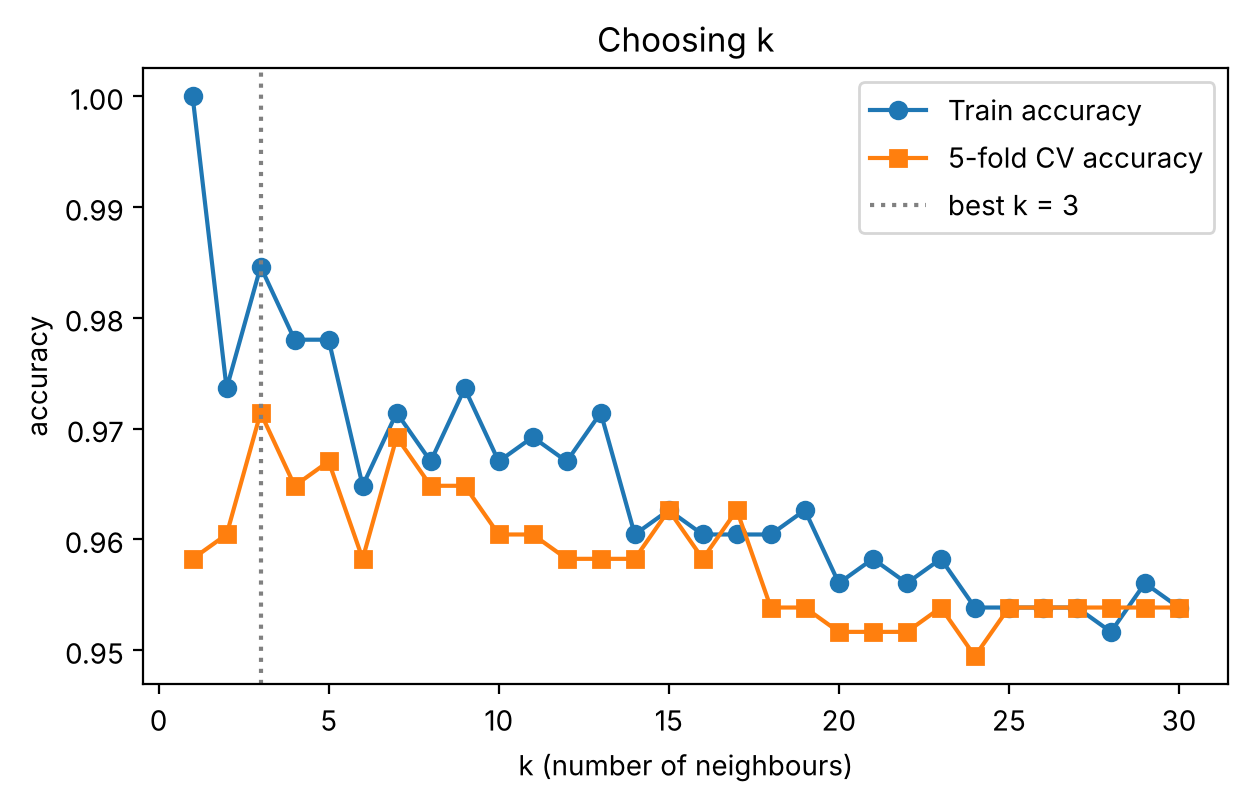

In [6]:
ks = range(1, 31)
skf = StratifiedKFold(5, shuffle=True, random_state=42)
cv_acc, train_acc = [], []
for kk in ks:
    m = KNeighborsClassifier(n_neighbors=kk)
    cv_acc.append(cross_val_score(m, Xs_train, y_train, cv=skf, scoring="accuracy").mean())
    train_acc.append(m.fit(Xs_train, y_train).score(Xs_train, y_train))
best_k = list(ks)[int(np.argmax(cv_acc))]
print(f"Best k by 5-fold CV accuracy: {best_k} (CV accuracy = {max(cv_acc):.4f})")

plt.figure(figsize=(7, 4))
plt.plot(ks, train_acc, "o-", label="Train accuracy")
plt.plot(ks, cv_acc, "s-", label="5-fold CV accuracy")
plt.axvline(best_k, color="gray", ls=":", label=f"best k = {best_k}")
plt.xlabel("k (number of neighbours)"); plt.ylabel("accuracy"); plt.title("Choosing k"); plt.legend(); plt.show()

## Step 5 — Final model and evaluation on the hold-out test set

TP             36.0000
TN             71.0000
FP              1.0000
FN              6.0000
Accuracy        0.9386
Error           0.0614
Recall          0.8571
Specificity     0.9861
Precision       0.9730
F1              0.9114
AUC             0.9825

              precision    recall  f1-score   support

      benign       0.92      0.99      0.95        72
   malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



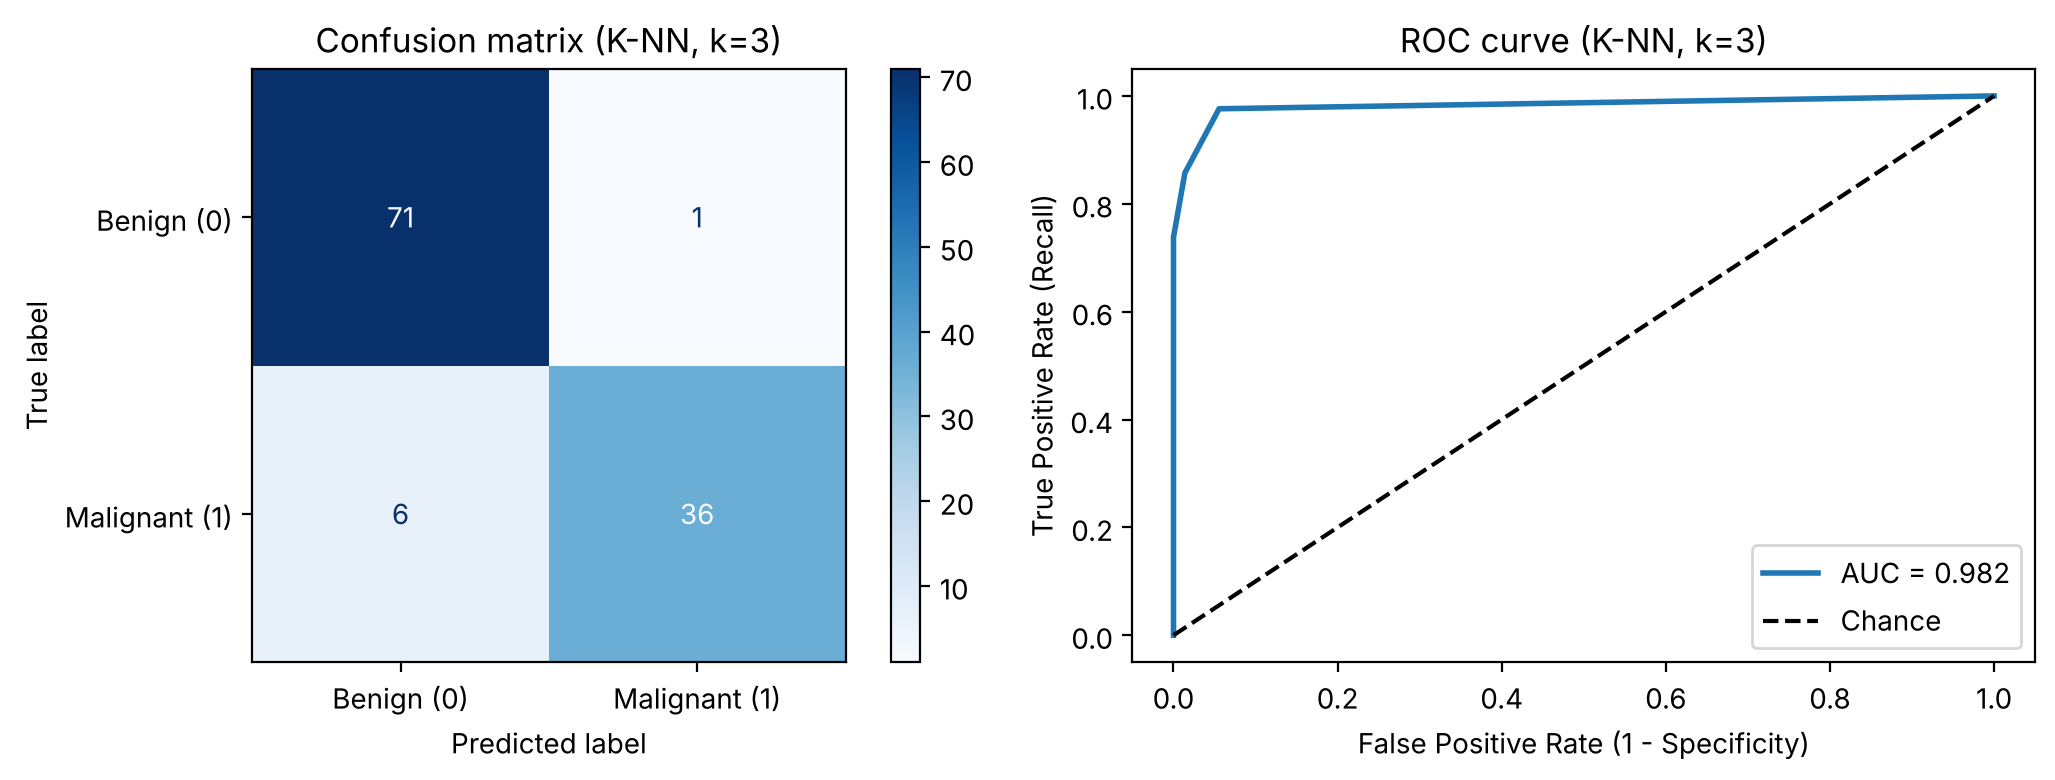

In [7]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xs_train, y_train)
y_pred = knn.predict(Xs_test)
test_m = classification_metrics(y_test, y_pred, knn.predict_proba(Xs_test)[:, 1])
print(test_m.round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))
plot_cm_roc(knn, Xs_test, y_test, title=f"(K-NN, k={best_k})")

## Step 6 — Why scaling matters
Same k, same split, but **without** standardisation:

In [8]:
knn_raw = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
raw_m = classification_metrics(y_test, knn_raw.predict(X_test), knn_raw.predict_proba(X_test)[:, 1])
display(pd.DataFrame({"Scaled": test_m, "Not scaled": raw_m}).loc[["Accuracy", "Recall", "Specificity", "F1", "AUC"]].round(4))

,Scaled,Not scaled
Accuracy,0.9386,0.9211
Recall,0.8571,0.7857
Specificity,0.9861,1.0000
F1,0.9114,0.8800
AUC,0.9825,0.8973


## Step 7 — Distance metric and weighting (optional experiment)

In [9]:
rows = []
for metric in ["euclidean", "manhattan", "chebyshev"]:
    for weights in ["uniform", "distance"]:
        m = KNeighborsClassifier(n_neighbors=best_k, metric=metric, weights=weights)
        rows.append({"metric": metric, "weights": weights,
                     "CV accuracy": cross_val_score(m, Xs_train, y_train, cv=skf).mean(),
                     "Test accuracy": m.fit(Xs_train, y_train).score(Xs_test, y_test)})
display(pd.DataFrame(rows).round(4))

,metric,weights,CV accuracy,Test accuracy
0,euclidean,uniform,0.9714,0.9386
1,euclidean,distance,0.9714,0.9386
2,manhattan,uniform,0.9758,0.9649
3,manhattan,distance,0.9758,0.9649
4,chebyshev,uniform,0.9516,0.9035
5,chebyshev,distance,0.9516,0.9035


## Step 8 — k-fold cross-validation (k = 5) of the final model
Pipeline = scaler + K-NN, so the scaler is fitted on the training folds only.

In [10]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
folds, summary = kfold_evaluate(pipe, X, y, k=5)
print()
display(folds.round(4)); display(summary.round(4))

Fold 1: train=455, test=114, accuracy=0.9912, AUC=0.9992
Fold 2: train=455, test=114, accuracy=0.9474, AUC=0.9741
Fold 3: train=455, test=114, accuracy=0.9561, AUC=0.9701
Fold 4: train=455, test=114, accuracy=0.9825, AUC=0.9987


Fold 5: train=456, test=113, accuracy=0.9558, AUC=0.9712



,TP,TN,FP,FN,Accuracy,Error,Recall,Specificity,Precision,F1,AUC
Fold 1,42.0,71.0,0.0,1.0,0.9912,0.0088,0.9767,1.0000,1.0000,0.9882,0.9992
Fold 2,38.0,70.0,1.0,5.0,0.9474,0.0526,0.8837,0.9859,0.9744,0.9268,0.9741
Fold 3,38.0,71.0,1.0,4.0,0.9561,0.0439,0.9048,0.9861,0.9744,0.9383,0.9701
Fold 4,42.0,70.0,2.0,0.0,0.9825,0.0175,1.0000,0.9722,0.9545,0.9767,0.9987
Fold 5,37.0,71.0,0.0,5.0,0.9558,0.0442,0.8810,1.0000,1.0000,0.9367,0.9712


,mean,std
TP,39.4000,2.4083
TN,70.6000,0.5477
FP,0.8000,0.8367
FN,3.0000,2.3452
Accuracy,0.9666,0.0191
Error,0.0334,0.0191
Recall,0.9292,0.0554
Specificity,0.9888,0.0116
Precision,0.9807,0.0194
F1,0.9534,0.0273


## Step 9 — Summary

In [11]:
display(pd.DataFrame({"Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

,Hold-out test,5-fold CV mean
TP,36.0000,39.4000
TN,71.0000,70.6000
FP,1.0000,0.8000
FN,6.0000,3.0000
Accuracy,0.9386,0.9666
Error,0.0614,0.0334
Recall,0.8571,0.9292
Specificity,0.9861,0.9888
Precision,0.9730,0.9807
F1,0.9114,0.9534


### Conclusion
* K-NN has no training phase – all work happens at prediction time (distance to every stored sample), so it becomes slow on very large datasets.
* The manual vote (distances → nearest k → majority) reproduces scikit-learn's prediction and probability.
* k controls the bias–variance trade-off; cross-validation on the training data picked a small odd k (printed in Step 4) – k = 1 over-fits, very large k under-fits.
* Feature scaling is mandatory for distance-based methods – without it the large-valued features dominate the distance and Recall and AUC drop noticeably (Step 6).